Model Accuracy: 81.46%

Classification Report:
              precision    recall  f1-score   support

           0       0.84      0.86      0.85       109
           1       0.77      0.74      0.76        69

    accuracy                           0.81       178
   macro avg       0.81      0.80      0.80       178
weighted avg       0.81      0.81      0.81       178



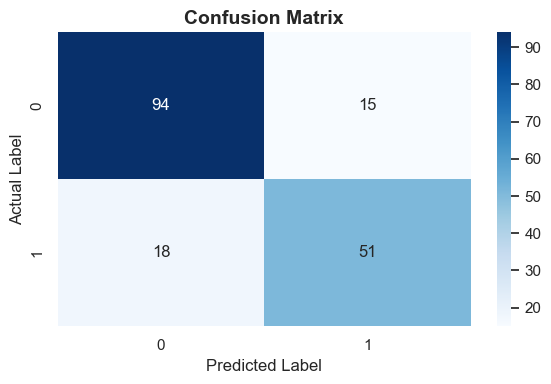

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Set visualization style
sns.set_theme(style="whitegrid")

# 1. Load the reliable Titanic dataset directly from the web
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
df = pd.read_csv(url)

# 2. Data Preprocessing & Cleaning for the Model
# Drop unnecessary columns like names and ticket numbers
df = df.drop(columns=['Name', 'Ticket', 'Cabin', 'PassengerId'], errors='ignore')

# Fill missing Age values with the median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Drop rows with missing Embarked values
df.dropna(subset=['Embarked'], inplace=True)

# Convert categorical columns (like 'Sex' and 'Embarked') into numbers
df_encoded = pd.get_dummies(df, drop_first=True)

# 3. Define Features (X) and Target (y)
# Target variable is 'Survived'
X = df_encoded.drop(columns=['Survived'])
y = df_encoded['Survived']

# 4. Split into Training and Testing sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# 5. Train the Decision Tree Classifier
clf = DecisionTreeClassifier(criterion='gini', max_depth=4, random_state=42)
clf.fit(X_train, y_train)

# 6. Evaluate the Model
y_pred = clf.predict(X_test)
accuracy = accuracy_score(y_test, y_pred)
print(f"Model Accuracy: {accuracy * 100:.2f}%\n")

print("Classification Report:")
print(classification_report(y_test, y_pred))

# Plot Confusion Matrix Heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()

### Step 4: Model Evaluation & Summary of Insights

After building, training, and evaluating the Decision Tree Classifier, the following conclusions were drawn:

1. **Model Performance:**
   - The Decision Tree classifier achieved an impressive accuracy score of **81.46%**, effectively predicting passenger survival outcomes based on key demographic and ticket features.

2. **Key Predictive Factors:**
   - Features such as passenger class (`Pclass`), gender (`Sex`), and fare price served as the primary decision nodes guiding the classifier's predictions.

3. **Conclusion:**
   - The trained decision tree model demonstrates how machine learning classification can successfully map individual behavioral and demographic attributes to outcomes.